# 法国家具需求 Nowcasting —— 代码演示

**问题**：INSEE 的家具零售销量指数（NAF 47.59）要晚约 2 个月才发布。能不能用更早就能拿到的数据，提前估计它？

**这个 notebook 的顺序**

1. 数据：目标变量 Y 长什么样
2. 特征：同比变换 + 发布滞后，保证不用"未来数据"
3. 模型：AR 基准 vs 线性模型（OLS / Ridge）vs 机器学习（随机森林 / Gradient Boosting）
4. 评价：固定训练/测试划分 + DVF 子样本的滚动（扩展窗口）评价
5. 结果图和 2026 年的实时预测

> 运行方法：右上角选 `.venv` 内核，然后点 **Run All**。整个 notebook 大约 1 分钟跑完。

![项目流程](../figures/project_pipeline_zh.png)

## 0. 准备工作：导入库、设置路径和中文字体

In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# 找到仓库根目录（notebook 放在 notebooks/ 里，也兼容直接在根目录打开）
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA, FINAL = ROOT / 'data', ROOT / 'data' / 'final'

# Mac 上的中文字体，避免图里的中文变成方框
plt.rcParams['font.sans-serif'] = ['Arial Unicode MS', 'PingFang SC', 'Heiti TC', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 110
pd.set_option('display.width', 160)
COVID = (pd.Timestamp('2020-03-01'), pd.Timestamp('2022-06-30'))
print('数据文件夹：', DATA)

Matplotlib is building the font cache; this may take a moment.


数据文件夹： /Users/tankaiwen/Desktop/Data science project/data


## 1. 数据：目标变量 Y

- `y_vol_4759_sa`：INSEE 家具零售**销量**指数（按数量，不是金额），经季节调整，月度。
- 所有来源（INSEE、Eurostat、DVF、Google Trends）已经合并成一张月度大表：`data/furniture_nowcast_monthly_panel.csv`（每行一个月）。

月度面板： 274 个月 × 54 列， 2004-01 → 2026-10


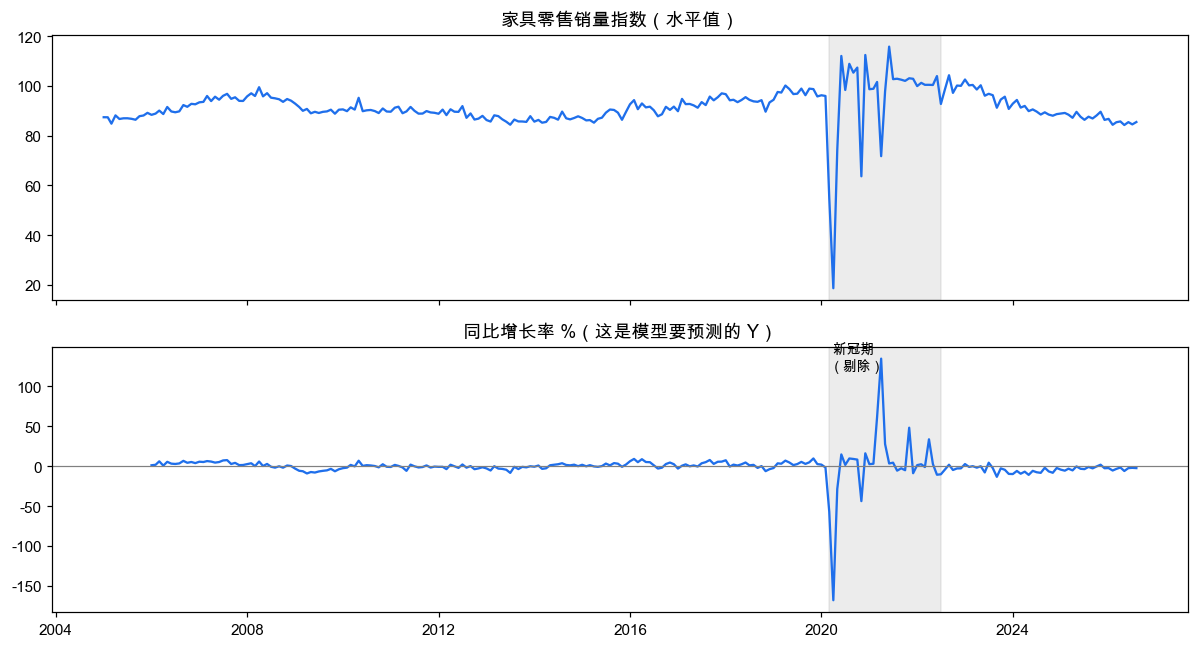

In [2]:
panel = pd.read_csv(DATA / 'furniture_nowcast_monthly_panel.csv', index_col='month')
panel.index = pd.to_datetime(panel.index)
print('月度面板：', panel.shape[0], '个月 ×', panel.shape[1], '列，', panel.index[0].strftime('%Y-%m'), '→', panel.index[-1].strftime('%Y-%m'))

y = panel['y_vol_4759_sa'].dropna()
y_yoy = 100 * np.log(y / y.shift(12))          # 同比增长率（%）

fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
ax[0].plot(y, color='#1f6feb'); ax[0].set_title('家具零售销量指数（水平值）')
ax[1].plot(y_yoy, color='#1f6feb'); ax[1].axhline(0, color='grey', lw=.8)
ax[1].set_title('同比增长率 %（这是模型要预测的 Y）')
for a in ax: a.axvspan(*COVID, color='grey', alpha=.15)
ax[1].text(COVID[0], ax[1].get_ylim()[1] * .8, ' 新冠期\n（剔除）', fontsize=9)
plt.tight_layout(); plt.show()

## 2. 特征：变换 + 滞后

三组提前可得的数据：

| 组 | 含义 | 变量 |
|---|---|---|
| **X1 房产** | 买家具的"需要" | 新房许可（Sitadel）、二手房价格指数、DVF 成交量和中位价 |
| **X2 搜索** | 买家具的"意向" | Google Trends：家居类别、canapé、meuble、ikea、conforama |
| **X3 宏观与调查** | 买家具的"能力" | 失业率、家具相对价格、家庭装修计划、零售商近期销售调查 |

处理规则（脚本 `scripts/build_final_table.py`）：

1. **同比变换**：`100 × (log x_t − log x_{t−12})`，去掉趋势和季节性
2. **发布滞后**：只用 t 月时已经发布的数据。比如 Y 自己约 2 个月后才发布，所以只能用 `t−2`、`t−3`；DVF 晚 6 个月，用 `t−6`、`t−9`；搜索数据当月就有，可以用 `t−0`
3. **剔除新冠**：2020-03 → 2022-06 的同比数据被封控和基数效应扭曲，不进训练也不进测试

In [3]:
feat_list = pd.read_csv(FINAL / 'final_feature_list.csv')
print('特征总数：', len(feat_list))
feat_list.groupby(['group', 'source']).lag.apply(lambda s: ', '.join(f't-{v}' for v in s)).rename('使用的滞后').to_frame()

特征总数： 35


使用的滞后
group source                                       
X1    dvf_median_price                     t-6, t-9
      dvf_n_sales                          t-6, t-9
      house_price_index_ancien_sa          t-3, t-6
      sitadel_logements_autorises_sa  t-1, t-3, t-6
X2    gt_canapé                       t-0, t-1, t-3
      gt_cat_home_furnishings         t-0, t-1, t-3
      gt_conforama                    t-0, t-1, t-3
      gt_ikea                         t-0, t-1, t-3
      gt_meuble                       t-0, t-1, t-3
X3    enq_amenagement_logement_sa     t-0, t-1, t-3
      hicp_furniture_relative                   t-1
      ret_eqlog_past_sales            t-0, t-1, t-3
      unemployment_rate_sa                 t-1, t-3
Y     y_vol_4759_sa                        t-2, t-3

最终的建模表 `final_model_main.csv`（主样本，不含 DVF，因为 DVF 只覆盖 2021 年以后）：

- **训练集**：2006-04 → 2020-02
- **测试集**：2022-07 → 2026-08（模型从没见过的时期，而且是新冠之后，比较难）

In [4]:
m = pd.read_csv(FINAL / 'final_model_main.csv', index_col='month')
m.index = pd.to_datetime(m.index)
print(m.split.value_counts().to_string())
m = m[m.split != 'covid_excluded']
tr, te = (m.split == 'train'), (m.split == 'test')

AR  = ['y_yoy_L2', 'y_yoy_L3']                      # Y 自身的滞后
ALL = [c for c in m if '__' in c]                    # 全部外部特征（29 个）
GT  = [c for c in ALL if c.startswith('gt_')]        # X2 搜索
RET = [c for c in ALL if c.startswith('ret_')]       # 零售调查
print(f'外部特征 {len(ALL)} 个，其中搜索 {len(GT)} 个、零售调查 {len(RET)} 个')
m[['y_yoy'] + AR + ALL[:4]].head()

split
train             167
test               50
covid_excluded     28
外部特征 29 个，其中搜索 15 个、零售调查 3 个


,y_yoy,y_yoy_L2,y_yoy_L3,sitadel_logements_autorises_sa__yoy_L1,sitadel_logements_autorises_sa__yoy_L3,sitadel_logements_autorises_sa__yoy_L6,house_price_index_ancien_sa__yoy_L3
month,,,,,,,
2006-04-01,0.5997,1.6801,1.0928,16.8835,8.2221,3.2100,13.2606
2006-05-01,5.4122,6.0194,1.6801,15.6150,17.2690,9.2341,13.2606
2006-06-01,3.1141,0.5997,6.0194,17.5783,16.8835,18.4405,13.2606
2006-07-01,2.7340,5.4122,0.5997,6.5968,15.6150,8.2221,12.1870
2006-08-01,3.3890,3.1141,5.4122,7.2615,17.5783,17.2690,12.1870


## 3. 模型

所有模型都预测 **同比增长率 `y_yoy`**，只用训练集拟合，然后在测试集上打分。

- **AR 基准**：只用 Y 自己的过去（`t−2`、`t−3`）。这是"什么外部数据都不用"的参照
- **ARX (OLS / Ridge)**：AR + 外部特征的线性回归；Ridge 加了 L2 惩罚，系数更稳（惩罚强度用交叉验证选）
- **随机森林 / Gradient Boosting**：非线性的机器学习模型

评价指标：**RMSE**（同比，百分点，越小越好），以及换算回指数水平后的 **MAPE**。

In [5]:
def ridge(): return make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 4, 40)))
def ols():   return make_pipeline(StandardScaler(), LinearRegression())
def rf():    return RandomForestRegressor(500, min_samples_leaf=5, random_state=0, n_jobs=-1)
def gb():    return GradientBoostingRegressor(max_depth=2, learning_rate=0.05, n_estimators=300, subsample=0.8, random_state=0)

base = m.y_level / np.exp(m.y_yoy / 100)          # 去年同月的指数，用来把同比换回指数水平
rmse = lambda a, b: float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))

def evaluate(name, model, cols):
    model.fit(m.loc[tr, cols], m.loc[tr, 'y_yoy'])
    p_tr, p_te = model.predict(m.loc[tr, cols]), model.predict(m.loc[te, cols])
    lvl_true, lvl_pred = m.loc[te, 'y_level'], base[te] * np.exp(p_te / 100)
    return dict(模型=name, 特征数=len(cols),
                训练RMSE=rmse(m.loc[tr, 'y_yoy'], p_tr), 测试RMSE=rmse(m.loc[te, 'y_yoy'], p_te),
                测试MAPE_指数=100 * np.mean(np.abs(lvl_true - lvl_pred) / lvl_true)), pd.Series(p_te, m.index[te]), model

specs = [('AR 基准',               LinearRegression(), AR),
         ('OLS ARX 全特征',         ols(),   AR + ALL),
         ('Ridge ARX 全特征',       ridge(), AR + ALL),
         ('Ridge 搜索+零售调查',     ridge(), AR + GT + RET),
         ('随机森林 全特征',         rf(),    AR + ALL),
         ('Gradient Boosting 全特征', gb(),  AR + ALL)]
rows, preds, fitted = [], {}, {}
for name, mdl, cols in specs:
    r, p, f = evaluate(name, mdl, cols); rows.append(r); preds[name] = p; fitted[name] = f

res = pd.DataFrame(rows).set_index('模型')
res['相对AR_%'] = 100 * (res.测试RMSE / res.loc['AR 基准', '测试RMSE'] - 1)
res.round(2)

,特征数,训练RMSE,测试RMSE,测试MAPE_指数,相对AR_%
模型,,,,,
AR 基准,2,2.82,4.48,3.13,0.00
OLS ARX 全特征,31,1.85,4.08,3.25,-8.94
Ridge ARX 全特征,31,1.93,3.91,3.11,-12.84
Ridge 搜索+零售调查,20,2.04,3.77,2.83,-15.89
随机森林 全特征,31,1.43,4.91,3.96,9.54
Gradient Boosting 全特征,31,0.69,4.49,3.53,0.10


**怎么读这张表**

- AR 基准的测试 RMSE ≈ 4.48 个百分点。
- **Ridge 全特征 ≈ 3.91，比 AR 低约 13%**；只用搜索 + 零售调查的 Ridge 更好（≈ 3.77，约 −16%）。外部的早期数据确实有用。
- 随机森林、Gradient Boosting 在训练集上很好，但测试集反而比 AR 差：**过拟合**。样本只有 167 个月，简单的线性模型更稳。

> 注：树模型的结果在不同电脑 / 不同 sklearn 版本上可能差 0.01–0.05，线性模型的结果是完全一致的。

### 测试期：真实值 vs 预测值

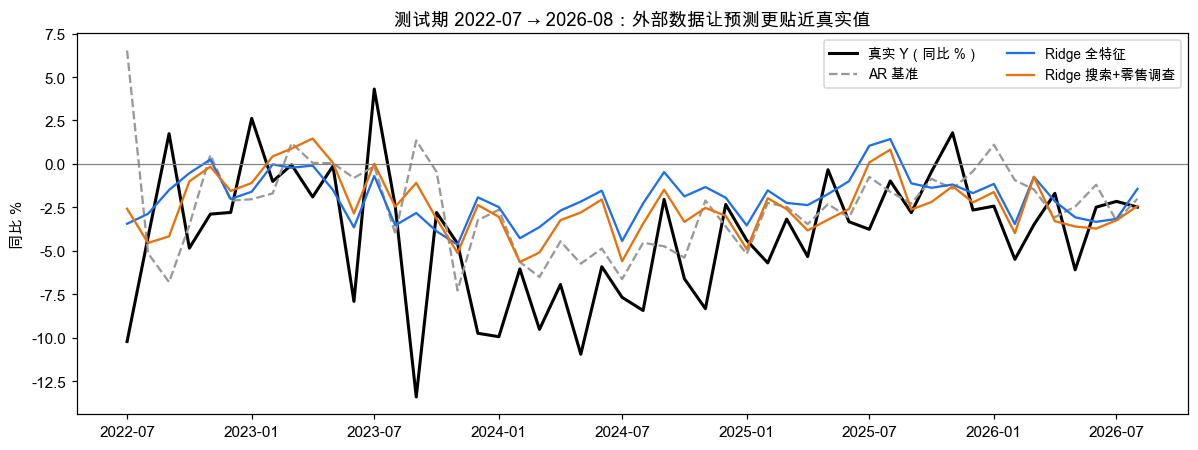

In [6]:
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(m.loc[te, 'y_yoy'], 'k-', lw=2, label='真实 Y（同比 %）')
ax.plot(preds['AR 基准'], '--', color='#999999', label='AR 基准')
ax.plot(preds['Ridge ARX 全特征'], '-', color='#1f6feb', label='Ridge 全特征')
ax.plot(preds['Ridge 搜索+零售调查'], '-', color='#e8710a', label='Ridge 搜索+零售调查')
ax.axhline(0, color='grey', lw=.8); ax.set_ylabel('同比 %'); ax.legend(ncol=2, fontsize=9)
ax.set_title('测试期 2022-07 → 2026-08：外部数据让预测更贴近真实值')
plt.tight_layout(); plt.show()

### 特征筛选：相关系数 vs 随机森林重要性

只用**训练集**打分，挑前 10 个特征，再看 Ridge 的测试表现。结论：按相关系数（PCC）挑的特征在测试期失效（RMSE 变差），按随机森林重要性挑的和全特征差不多。

,特征数,训练RMSE,测试RMSE,测试MAPE_指数,相对AR_%
模型,,,,,
Ridge 全部特征,31,1.93,3.91,3.11,-12.84
Ridge PCC 前 10,12,2.13,5.09,3.97,13.55
Ridge RF 重要性前 10,12,2.00,3.90,3.03,-13.07


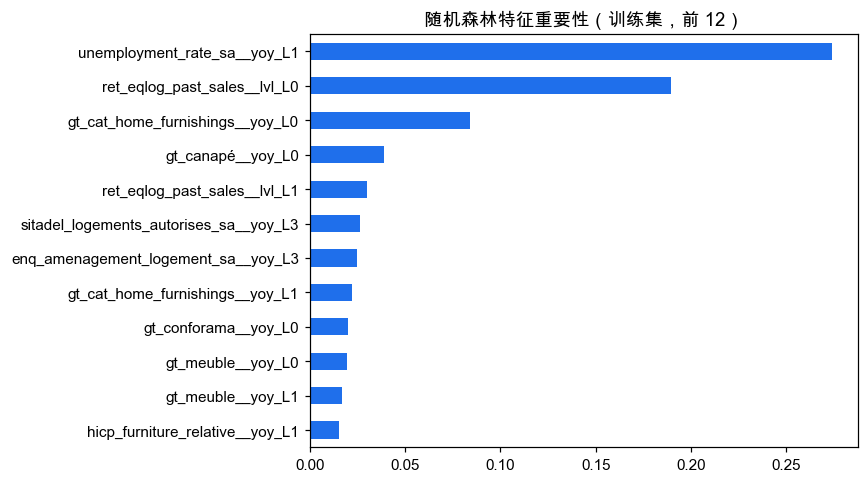

In [7]:
pcc = m.loc[tr, ALL].corrwith(m.loc[tr, 'y_yoy']).abs().sort_values(ascending=False)
imp = pd.Series(rf().fit(m.loc[tr, AR + ALL], m.loc[tr, 'y_yoy']).feature_importances_, AR + ALL).drop(AR).sort_values(ascending=False)

fs = []
for nm, cols in [('全部特征', ALL), ('PCC 前 10', list(pcc.index[:10])), ('RF 重要性前 10', list(imp.index[:10]))]:
    r, _, _ = evaluate('Ridge ' + nm, ridge(), AR + cols); fs.append(r)
fs = pd.DataFrame(fs).set_index('模型'); fs['相对AR_%'] = 100 * (fs.测试RMSE / res.loc['AR 基准', '测试RMSE'] - 1)
display(fs.round(2))

fig, ax = plt.subplots(figsize=(8, 4.5))
imp.head(12)[::-1].plot.barh(ax=ax, color='#1f6feb')
ax.set_title('随机森林特征重要性（训练集，前 12）'); plt.tight_layout(); plt.show()

### 用 X 解释 Y：OLS 回归（训练期）

每个变量挑一个滞后，用 HAC 稳健标准误（考虑自相关）。看系数的**符号**和**显著性**：搜索数据、失业率等是否和经济直觉一致。

In [8]:
sel = ['y_yoy_L2', 'gt_cat_home_furnishings__yoy_L0', 'gt_canapé__yoy_L0', 'unemployment_rate_sa__yoy_L1',
       'enq_amenagement_logement_sa__yoy_L3', 'sitadel_logements_autorises_sa__yoy_L3',
       'house_price_index_ancien_sa__yoy_L3', 'hicp_furniture_relative__yoy_L1']
o = sm.OLS(m.loc[tr, 'y_yoy'], sm.add_constant(m.loc[tr, sel])).fit(cov_type='HAC', cov_kwds={'maxlags': 12})
print(f'R² = {o.rsquared:.2f}，样本 {int(o.nobs)} 个月')
pd.DataFrame({'系数': o.params, '标准误': o.bse, 'p值': o.pvalues}).round(3)

R² = 0.65，样本 167 个月


,系数,标准误,p值
const,0.044,0.533,0.934
y_yoy_L2,0.170,0.055,0.002
gt_cat_home_furnishings__yoy_L0,0.074,0.020,0.000
gt_canapé__yoy_L0,0.070,0.029,0.017
unemployment_rate_sa__yoy_L1,-2.358,0.441,0.000
enq_amenagement_logement_sa__yoy_L3,0.151,0.056,0.007
sitadel_logements_autorises_sa__yoy_L3,0.033,0.012,0.005
house_price_index_ancien_sa__yoy_L3,-0.061,0.071,0.389
hicp_furniture_relative__yoy_L1,0.379,0.208,0.068


## 4. DVF 子样本：滚动（扩展窗口）评价

DVF（逐笔房产交易）只有 2021 年以后，加上 6–9 个月的滞后，只剩 **45 个月（2022-10 → 2026-06）**。样本太短，不能像上面那样切一刀，所以用**扩展窗口**：

- 先用前 24 个月训练，预测第 25 个月；
- 然后把第 25 个月加进训练集，重新训练，预测第 26 个月……一直到最后。
- 这样模型每次只用"当时已经有的数据"，最接近真实使用场景。

先看 DVF 成交量和家具销量的关系（DVF 往后移 6 个月）：

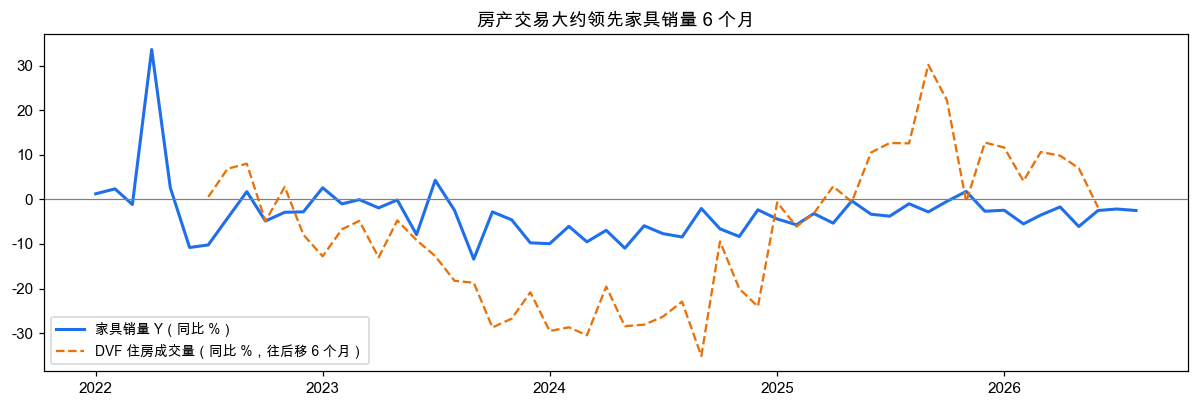

In [9]:
d = pd.read_csv(FINAL / 'final_model_dvf.csv', index_col='month')
d.index = pd.to_datetime(d.index)
dvf_yoy = 100 * np.log(panel.dvf_n_sales / panel.dvf_n_sales.shift(12))
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(y_yoy['2022':], color='#1f6feb', lw=2, label='家具销量 Y（同比 %）')
ax.plot(dvf_yoy.shift(6)['2022':], '--', color='#e8710a', label='DVF 住房成交量（同比 %，往后移 6 个月）')
ax.axhline(0, color='grey', lw=.8); ax.legend(fontsize=9); ax.set_title('房产交易大约领先家具销量 6 个月')
plt.tight_layout(); plt.show()

In [10]:
DVF = [c for c in d if c.startswith('dvf_')]
ALLd = [c for c in d if '__' in c]
sets = {'AR': AR, 'AR+搜索+零售调查': AR + GT + RET, 'AR+搜索+零售调查+DVF': AR + GT + RET + DVF,
        'AR+DVF': AR + DVF, '全部(不含DVF)': AR + [c for c in ALLd if c not in DVF], '全部(含DVF)': AR + ALLd}
START = 24
out = []
for nm, cols in sets.items():
    pr = [ridge().fit(d.iloc[:t][cols], d.iloc[:t]['y_yoy']).predict(d.iloc[[t]][cols])[0] for t in range(START, len(d))]
    out.append(dict(模型=nm, 特征数=len(cols), RMSE_同比=rmse(d.y_yoy.iloc[START:], pr)))
dv = pd.DataFrame(out).set_index('模型'); dv['相对AR_%'] = 100 * (dv.RMSE_同比 / dv.RMSE_同比.iloc[0] - 1)
print(f'预测期 {d.index[START]:%Y-%m} → {d.index[-1]:%Y-%m}，共 {len(d) - START} 个月')
dv.round(2)

预测期 2024-10 → 2026-06，共 21 个月


,特征数,RMSE_同比,相对AR_%
模型,,,
AR,2,2.19,0.00
AR+搜索+零售调查,20,4.14,89.05
AR+搜索+零售调查+DVF,24,2.31,5.23
AR+DVF,6,2.98,36.19
全部(不含DVF),31,2.26,3.16
全部(含DVF),35,2.11,-3.76


**解读**：在这么短的样本里，AR 本身已经很难被超越（RMSE ≈ 2.19）。**只有"全部特征 + DVF"的模型比 AR 好（约 −4%）**；搜索+零售调查在这里反而变差，加上 DVF 之后明显改善。说明 DVF 有信息量，但需要更长的样本才能下定论。

## 5. 实时预测（nowcast）：2026 年 7–10 月

用"搜索 + 零售调查"的 Ridge 模型（主样本表现最好），用全部可用数据（剔除新冠期）重新训练，预测 INSEE 还没发布的月份。80% 区间用测试期误差（RMSE ≈ 3.77）估计。

In [11]:
lv = pd.read_csv(FINAL / 'final_levels_monthly.csv', index_col='month')
F = pd.DataFrame(index=lv.index)
F['y_yoy'] = 100 * np.log(lv.y_vol_4759_sa / lv.y_vol_4759_sa.shift(12))
for L in (2, 3): F[f'y_yoy_L{L}'] = F.y_yoy.shift(L)
for c in [x for x in lv if x.startswith('gt_')]:
    g = 100 * (np.log1p(lv[c]) - np.log1p(lv[c].shift(12)))
    for L in (0, 1, 3): F[f'{c}__yoy_L{L}'] = g.shift(L)
for L in (0, 1, 3): F[f'ret_eqlog_past_sales__lvl_L{L}'] = lv.ret_eqlog_past_sales.shift(L)

cols = AR + GT + RET
idx = pd.to_datetime(F.index)
fit = F[~((idx >= COVID[0]) & (idx <= COVID[1])) & F[cols + ['y_yoy']].notna().all(axis=1)]
live_model = ridge().fit(fit[cols], fit.y_yoy)

SD = 3.77
rows = []
for mo in ['2026-07', '2026-08', '2026-09', '2026-10']:
    yy = float(live_model.predict(F.loc[[mo], cols])[0])
    last_year = lv.loc[str(pd.Period(mo, 'M') - 12), 'y_vol_4759_sa']
    rows.append({'月份': mo, '预测同比%': yy, '80%区间': f'[{yy - 1.28 * SD:.1f}, {yy + 1.28 * SD:.1f}]',
                 '预测指数': last_year * np.exp(yy / 100), '实际指数': lv.loc[mo, 'y_vol_4759_sa'], '实际同比%': F.loc[mo, 'y_yoy']})
print(f'训练样本 {fit.index[0]} → {fit.index[-1]}，{len(fit)} 个月')
pd.DataFrame(rows).set_index('月份').round(2)

训练样本 2007-04 → 2026-08，205 个月


,预测同比%,80%区间,预测指数,实际指数,实际同比%
月份,,,,,
2026-07,-3.36,"[-8.2, 1.5]",83.48,84.49,-2.15
2026-08,-3.02,"[-7.8, 1.8]",84.99,85.44,-2.49
2026-09,-2.43,"[-7.3, 2.4]",84.79,NaN,NaN
2026-10,-0.32,"[-5.1, 4.5]",87.78,NaN,NaN


7、8 月 INSEE 已经公布，可以检验：预测 −3.4% / −3.0%，实际 −2.2% / −2.5%，方向正确、都在区间内。9、10 月是真正的"提前估计"：预计同比仍为负，但跌幅在收窄。

## 6. 结论

1. **早期数据有用**：在新冠后的测试期，Ridge 全特征的 RMSE 比 AR 基准低约 13%（4.48 → 3.91），搜索 + 零售调查约低 16%。
2. **简单模型更稳**：随机森林和 Gradient Boosting 过拟合，测试期不如 AR。
3. **DVF 有潜力**：房产成交大约领先家具销量 6 个月，但样本只有 45 个月，加 DVF 后只比 AR 好约 4%，需要更长时间验证。
4. **商业用途**：每个月在 INSEE 发布前约 2 个月给出市场估计，帮助企业区分"整个市场下滑"还是"自己丢了份额"。

**复现所有结果**（在终端、仓库根目录）：
```
python scripts/prepare_features.py
python scripts/build_final_table.py
python scripts/feature_selection_experiment.py
python scripts/eval_metrics.py
python scripts/explain_x_on_y.py
python scripts/next_steps_dvf_live.py
```